# Porównanie 4 modeli ML – predykcja bankructwa
HistGradientBoosting, XGBoost, Random Forest, Logistic Regression. Metryka główna: Average Precision (klasy silnie niezbalansowane).

## 1. Biblioteki

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.io import arff

from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import QuantileTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.inspection import permutation_importance
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve,
                             precision_score, recall_score, f1_score)
from xgboost import XGBClassifier

## 2. Wczytanie danych

In [10]:
sciezka = Path('5year.arff')
rekordy, meta = arff.loadarff(sciezka)
X = pd.DataFrame({n.replace('Attr', 'X'): rekordy[n].astype(float)
                  for n in rekordy.dtype.names if n != 'class'})
y = pd.Series([int(v.decode('ascii')) for v in rekordy['class']], name='y')
print('Plik:', sciezka.resolve())

Plik: C:\Users\marcz\Desktop\Projekt_inzynierski-main\Bankructwo Polskie firmy\modele\5year.arff


## 3. Kontrola jakości danych
Sprawdzenia: wymiary, typy, balans klas, wartości nieskończone, kolumny stałe, puste wiersze, duplikaty (także z różną etykietą).

In [11]:
print('Kształt:', X.shape)
print('Typy:', X.dtypes.unique())
print('Klasy:', y.value_counts().to_dict(), f'| bankructwa: {y.mean():.2%}')
print('Wartości inf:', int(np.isinf(X).sum().sum()))
print('Kolumny stałe:', int((X.nunique() <= 1).sum()))
print('Wiersze w pełni puste:', int(X.isna().all(axis=1).sum()))

pelne = pd.concat([X, y], axis=1)
print('Duplikaty (cechy + etykieta):', int(pelne.duplicated().sum()))
print('Duplikaty cech z różną etykietą:', int(pelne.drop_duplicates().duplicated(subset=X.columns).sum()))

Kształt: (5910, 64)
Typy: [dtype('float64')]
Klasy: {0: 5500, 1: 410} | bankructwa: 6.94%
Wartości inf: 0
Kolumny stałe: 0
Wiersze w pełni puste: 0
Duplikaty (cechy + etykieta): 60
Duplikaty cech z różną etykietą: 0


## 4. Brakujące wartości – analiza
Braki wynikają głównie z dzielenia przez zero lub braku historii, nie są losowe:
- X37 (43%) – brak zobowiązań długoterminowych w mianowniku
- X27 – brak kosztów finansowych; X45, X60 – brak zapasów; X28, X53, X54, X64 – brak środków trwałych
- X21 – brak sprzedaży z poprzedniego roku; X24 – brak historii 3 lat

Sprawdzamy, czy sam fakt braku niesie informację o klasie.

In [12]:
braki = X.isna().mean().sort_values(ascending=False)
display(braki[braki > 0].head(10).round(3).to_frame('udział braków'))
print('Kolumny z brakami:', int((braki > 0).sum()), '| wiersze z brakiem:', f'{X.isna().any(axis=1).mean():.1%}')
print('Średnia liczba braków na wiersz:', X.isna().sum(axis=1).groupby(y).mean().round(2).to_dict())
print('ROC-AUC liczby braków vs klasa:', round(roc_auc_score(y, X.isna().sum(axis=1)), 3))

,udział braków
X37,0.431
X27,0.066
X45,0.045
X60,0.045
X24,0.023
X54,0.018
X28,0.018
X53,0.018
X64,0.018
X21,0.017


Kolumny z brakami: 49 | wiersze z brakiem: 48.7%
Średnia liczba braków na wiersz: {0: 0.73, 1: 1.57}
ROC-AUC liczby braków vs klasa: 0.681


## 5. Wartości odstające i współliniowość
Ratio finansowe mają ekstremalne wartości (mianownik bliski zera). Nie usuwamy ich – ekstremum bywa sygnałem upadłości; modele drzewiowe są odporne, a dla regresji logistycznej użyjemy transformacji kwantylowej.

In [13]:
opis = X.describe(percentiles=[.01, .99]).T[['min', '1%', '99%', 'max']]
print('Cechy z |skośnością| > 10:', int((X.skew().abs() > 10).sum()), 'z', X.shape[1])
display(opis.loc[opis['max'].abs().sort_values(ascending=False).index[:5]].round(1))

kor = X.corr(method='spearman').abs()
gora = kor.where(np.triu(np.ones(kor.shape, dtype=bool), 1)).stack()
print('Pary cech o |Spearman| > 0.95:', int((gora > 0.95).sum()))
display(gora.sort_values(ascending=False).head(5).round(3).to_frame('|rho|'))

Cechy z |skośnością| > 10: 63 z 64


,min,1%,99%,max
X60,-12.4,1.3,686.7,4818700.0
X32,-255.1,7.1,997.4,4277200.0
X55,-1118500.0,-46437.9,184742.4,4212200.0
X15,-9632400.0,-21663.6,37792.2,1341700.0
X5,-1076400.0,-708.9,689.9,1250100.0


Pary cech o |Spearman| > 0.95: 34


|rho|
X14 X18  1.000
X7  X14  1.000
    X18  0.999
X20 X60  0.999
X2  X17  0.999

## 6. Duplikaty i podział danych

In [14]:
dane = pelne.drop_duplicates().reset_index(drop=True)
y = dane.pop('y')
X = dane

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

print('Po usunięciu duplikatów:', X.shape)
print('Train:', X_train.shape, f'(bankructwa {y_train.mean():.2%})')
print('Test: ', X_test.shape, f'(bankructwa {y_test.mean():.2%})')
print('Baseline AP (losowy klasyfikator):', round(y_train.mean(), 4))

Po usunięciu duplikatów: (5850, 64)
Train: (4680, 64) (bankructwa 6.97%)
Test:  (1170, 64) (bankructwa 7.01%)
Baseline AP (losowy klasyfikator): 0.0697


## 7. Modele

In [15]:
modele = {
    'HistGradientBoosting': HistGradientBoostingClassifier(
        max_iter=200, learning_rate=0.05, max_leaf_nodes=15,
        min_samples_leaf=30, l2_regularization=1.0, random_state=42),
    'XGBoost': XGBClassifier(
        n_estimators=200, max_depth=3, learning_rate=0.05,
        min_child_weight=5, subsample=0.8, colsample_bytree=0.8,
        eval_metric='logloss', tree_method='hist', random_state=42, n_jobs=2),
    'RandomForest': RandomForestClassifier(
        n_estimators=250, max_features='sqrt', min_samples_leaf=3,
        class_weight='balanced_subsample', random_state=42, n_jobs=-1),
    'LogisticRegression': LogisticRegression(
        C=0.2, class_weight='balanced', max_iter=3000, solver='lbfgs', random_state=42)
}

imputery = {
    'mediana': lambda: SimpleImputer(strategy='median'),
    'mediana+wskaźnik': lambda: SimpleImputer(strategy='median', add_indicator=True),
    'stała+wskaźnik': lambda: SimpleImputer(strategy='constant', fill_value=-999, add_indicator=True),
}

def zbuduj(nazwa, imputacja):
    kroki = [('imputer', imputery[imputacja]())]
    if nazwa == 'LogisticRegression':
        kroki.append(('scaler', QuantileTransformer(output_distribution='normal', n_quantiles=500, random_state=42)))
    kroki.append(('model', clone(modele[nazwa])))
    return Pipeline(kroki)

## 8. Wybór strategii imputacji

In [16]:
metryki = {'AP': 'average_precision', 'ROC_AUC': 'roc_auc'}
wszystkie = {}
for nazwa in modele:
    for imp in imputery:
        s = cross_validate(zbuduj(nazwa, imp), X_train, y_train, cv=cv, scoring=metryki, n_jobs=1)
        wszystkie[(nazwa, imp)] = {'AP': s['test_AP'].mean(), 'AP_STD': s['test_AP'].std(), 'ROC_AUC': s['test_ROC_AUC'].mean()}

porownanie = pd.DataFrame(wszystkie).T
display(porownanie['AP'].unstack().round(4))
wybor = porownanie['AP'].unstack().idxmax(axis=1)
print('Wybrana imputacja:', wybor.to_dict())

,mediana,mediana+wskaźnik,stała+wskaźnik
HistGradientBoosting,0.7520,0.7831,0.7791
LogisticRegression,0.4506,0.6659,0.6684
RandomForest,0.4730,0.5523,0.6019
XGBoost,0.7334,0.7651,0.7582


Wybrana imputacja: {'HistGradientBoosting': 'mediana+wskaźnik', 'LogisticRegression': 'stała+wskaźnik', 'RandomForest': 'stała+wskaźnik', 'XGBoost': 'mediana+wskaźnik'}


## 9. Ranking modeli (CV, wybrana imputacja)

In [17]:
finalne = {n: zbuduj(n, wybor[n]) for n in modele}
ranking = pd.DataFrame([{'Model': n, 'Imputacja': wybor[n], **porownanie.loc[(n, wybor[n])]} for n in modele])
ranking = ranking.sort_values('AP', ascending=False).reset_index(drop=True)
display(ranking.round(4))

,Model,Imputacja,AP,AP_STD,ROC_AUC
0,HistGradientBoosting,mediana+wskaźnik,0.7831,0.0409,0.9510
1,XGBoost,mediana+wskaźnik,0.7651,0.0441,0.9470
2,LogisticRegression,stała+wskaźnik,0.6684,0.0665,0.9311
3,RandomForest,stała+wskaźnik,0.6019,0.0514,0.9322


## 10. Ocena na zbiorze testowym

,Model,AP,ROC_AUC,Próg,Precision,Recall,F1
0,HistGradientBoosting,0.8475,0.9697,0.3508,0.8533,0.7805,0.8153
1,XGBoost,0.8326,0.9634,0.3086,0.8052,0.7561,0.7799
2,LogisticRegression,0.7212,0.9434,0.9075,0.6711,0.6220,0.6456
3,RandomForest,0.6560,0.9522,0.3366,0.6064,0.6951,0.6477


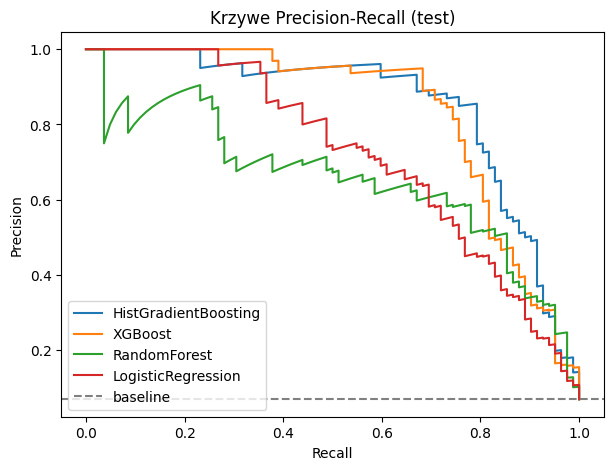

In [18]:
wyniki_test, krzywe = [], {}
for nazwa, p in finalne.items():
    oof = cross_val_predict(clone(p), X_train, y_train, cv=cv, method='predict_proba')[:, 1]
    pr, rc, th = precision_recall_curve(y_train, oof)
    prog = th[np.argmax((2 * pr * rc / (pr + rc + 1e-12))[:-1])]

    p.fit(X_train, y_train)
    proba = p.predict_proba(X_test)[:, 1]
    pred = (proba >= prog).astype(int)
    krzywe[nazwa] = precision_recall_curve(y_test, proba)[:2]
    wyniki_test.append({
        'Model': nazwa, 'AP': average_precision_score(y_test, proba), 'ROC_AUC': roc_auc_score(y_test, proba),
        'Próg': prog, 'Precision': precision_score(y_test, pred), 'Recall': recall_score(y_test, pred),
        'F1': f1_score(y_test, pred)})

wyniki_test = pd.DataFrame(wyniki_test).sort_values('AP', ascending=False).reset_index(drop=True)
display(wyniki_test.round(4))

plt.figure(figsize=(7, 5))
for n, (pr, rc) in krzywe.items():
    plt.plot(rc, pr, label=n)
plt.axhline(y_test.mean(), ls='--', c='gray', label='baseline')
plt.xlabel('Recall'); plt.ylabel('Precision'); plt.legend(); plt.title('Krzywe Precision-Recall (test)')
plt.show()

## 11. Które wskaźniki mają największy wpływ na model?

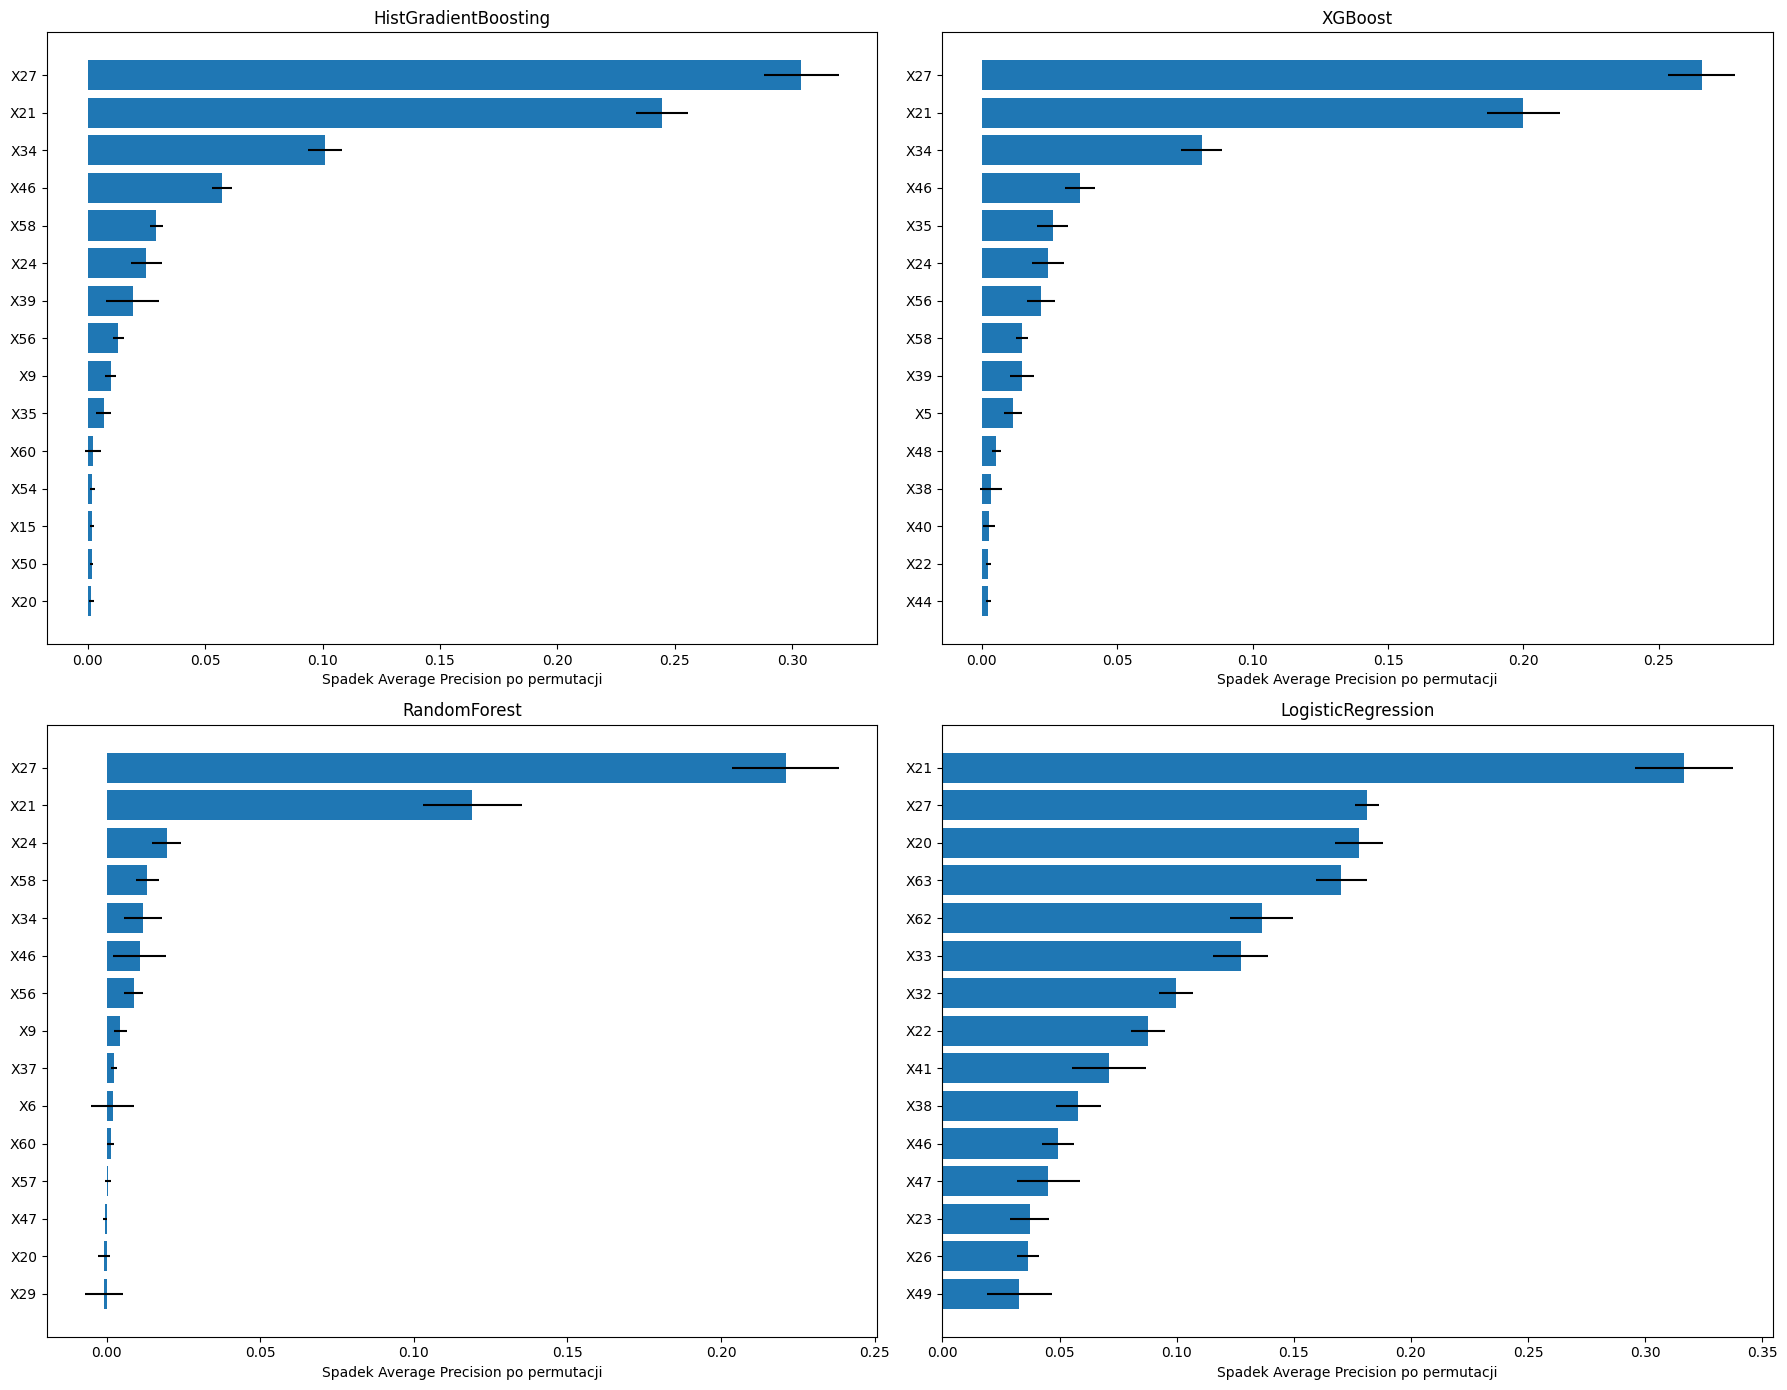

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(18, 14))
for ax, (nazwa, p) in zip(axes.flatten(), finalne.items()):
    imp = permutation_importance(p, X_test, y_test, scoring='average_precision',
                                 n_repeats=5, random_state=42, n_jobs=1)
    idx = np.argsort(imp.importances_mean)[-15:]
    ax.barh(X.columns[idx], imp.importances_mean[idx], xerr=imp.importances_std[idx])
    ax.set_title(nazwa)
    ax.set_xlabel('Spadek Average Precision po permutacji')
plt.tight_layout()
plt.show()

## 12. Wnioski

In [20]:
print('Ranking CV (AP):')
for _, r in ranking.iterrows():
    print(f"{r['Model']} [{r['Imputacja']}]: AP={r['AP']:.4f}±{r['AP_STD']:.4f}, ROC-AUC={r['ROC_AUC']:.4f}")
print('\nRanking test (AP):')
for _, r in wyniki_test.iterrows():
    print(f"{r['Model']}: AP={r['AP']:.4f}, ROC-AUC={r['ROC_AUC']:.4f}, F1={r['F1']:.3f}")
print('\nNajlepszy model (CV):', ranking.iloc[0]['Model'])

Ranking CV (AP):
HistGradientBoosting [mediana+wskaźnik]: AP=0.7831±0.0409, ROC-AUC=0.9510
XGBoost [mediana+wskaźnik]: AP=0.7651±0.0441, ROC-AUC=0.9470
LogisticRegression [stała+wskaźnik]: AP=0.6684±0.0665, ROC-AUC=0.9311
RandomForest [stała+wskaźnik]: AP=0.6019±0.0514, ROC-AUC=0.9322

Ranking test (AP):
HistGradientBoosting: AP=0.8475, ROC-AUC=0.9697, F1=0.815
XGBoost: AP=0.8326, ROC-AUC=0.9634, F1=0.780
LogisticRegression: AP=0.7212, ROC-AUC=0.9434, F1=0.646
RandomForest: AP=0.6560, ROC-AUC=0.9522, F1=0.648

Najlepszy model (CV): HistGradientBoosting
